# Lab 11: Attention

Name: Nawaf Mohammed Alghamdi

ID: 2240007352


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
%pip -q install pandas torch matplotlib tensorflow

import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

torch.manual_seed(42)


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: /Users/nawaf/Documents/Codex/2026-11-02/referenced-chatgpt-conversation-this-is-an/work/venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## Step 2 — Upload the dataset

In [2]:
dataset_path = Path("Lab_11_QnA_Dataset.csv")
if not dataset_path.exists():
    dataset_path = Path("/content/Lab_11_QnA_Dataset.csv")
df = pd.read_csv(dataset_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        padding_mask = x.eq(0)
        x, _ = self.rnn(self.emb(x))
        scores = self.att(x).squeeze(-1).masked_fill(padding_mask, float("-inf"))
        weights = torch.softmax(scores, dim=1)
        return self.fc((x * weights.unsqueeze(-1)).sum(1)), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

model.train()
for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")
model.eval()
with torch.no_grad():
    training_logits, _ = model(X)
    training_accuracy = (training_logits.argmax(dim=1) == y).float().mean().item()
print(f"Final training loss: {loss.item():.4f}")
print(f"Training accuracy: {training_accuracy:.2%}")
print("These are training-set results; no held-out generalization accuracy is measured in this lab.")

Training finished!
Final training loss: 0.0688
Training accuracy: 98.81%
These are training-set results; no held-out generalization accuracy is measured in this lab.


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

Question: do you get hurt?
Highest attention: get (0.8931)
Predicted answer group: 0; actual: 0
Question: who programmed you?
Highest attention: who (0.4226)
Predicted answer group: 3; actual: 3
Question: how do you feel about artificial intelligence?
Highest attention: about (0.8225)
Predicted answer group: 9; actual: 9


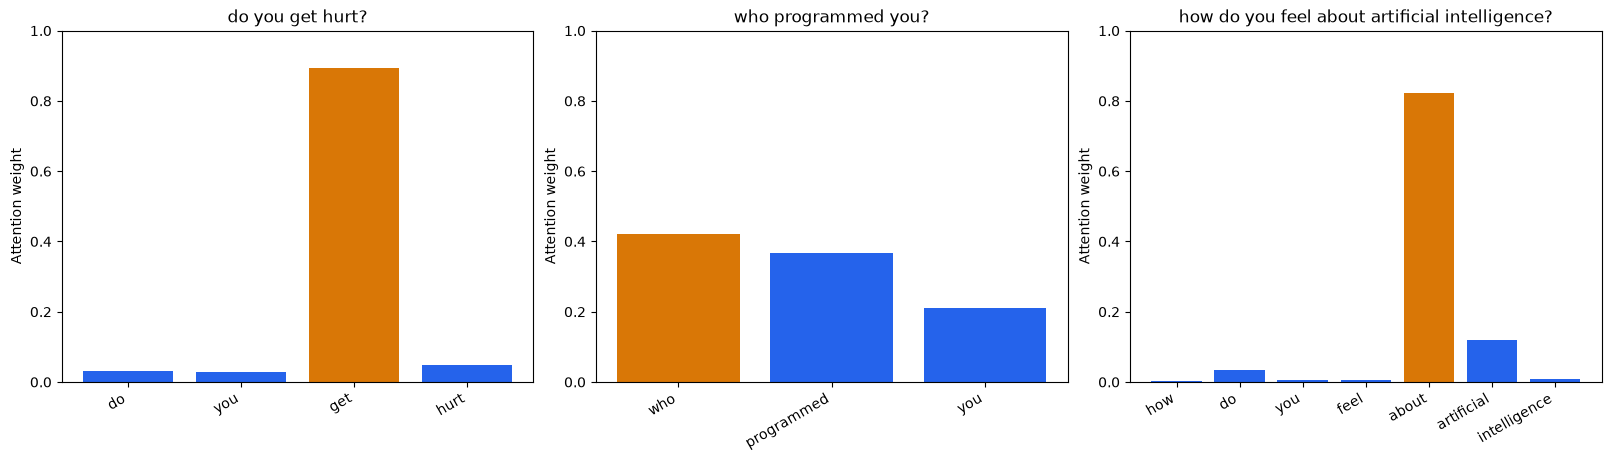

In [6]:
def show_attention(row_index, ax):
    question = df.loc[row_index, "question"]
    token_ids = X[row_index][X[row_index].ne(0)].tolist()
    words = [tokenizer.index_word[word_id] for word_id in token_ids]
    with torch.no_grad():
        prediction, weights = model(X[row_index:row_index + 1])
    word_weights = weights[0, :len(words)].cpu().tolist()
    highest_index = int(torch.argmax(weights[0, :len(words)]).item())
    colors = ["#d97706" if i == highest_index else "#2563eb" for i in range(len(words))]
    ax.bar(range(len(words)), word_weights, color=colors)
    ax.set_xticks(range(len(words)), words, rotation=30, ha="right")
    ax.set_ylim(0, 1)
    ax.set_ylabel("Attention weight")
    ax.set_title(question)
    result = {
        "question": question,
        "top_word": words[highest_index],
        "top_weight": word_weights[highest_index],
        "predicted_answer_id": prediction.argmax(dim=1).item(),
        "actual_answer_id": int(y[row_index]),
    }
    print(f"Question: {question}")
    print(f"Highest attention: {result['top_word']} ({result['top_weight']:.4f})")
    print(f"Predicted answer group: {result['predicted_answer_id']}; actual: {result['actual_answer_id']}")
    return result

selected_indices = [0, 42, 126]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
task1_results = [show_attention(index, ax) for index, ax in zip(selected_indices, axes)]
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

In [7]:
for result in task1_results:
    print(f"{result['question']} -> {result['top_word']} ({result['top_weight']:.4f})")
print("For 'do you get hurt?', the largest weight is on 'get', which contributes to the action phrase, although 'hurt' conveys the specific topic more directly.")
print("For 'who programmed you?', 'who' receives the largest weight and signals a question about a creator, while 'programmed' supplies the more specific meaning.")
print("For the artificial-intelligence question, the model emphasizes 'about', a function word rather than the topic words 'artificial intelligence'.")
print("Thus, the highest-weight words are only partly aligned with intuitive importance. The model learns dataset-specific associations, and each RNN hidden state represents a prefix of the question rather than an isolated word. Attention weights alone do not establish why a prediction was made.")

do you get hurt? -> get (0.8931)
who programmed you? -> who (0.4226)
how do you feel about artificial intelligence? -> about (0.8225)
For 'do you get hurt?', the largest weight is on 'get', which contributes to the action phrase, although 'hurt' conveys the specific topic more directly.
For 'who programmed you?', 'who' receives the largest weight and signals a question about a creator, while 'programmed' supplies the more specific meaning.
For the artificial-intelligence question, the model emphasizes 'about', a function word rather than the topic words 'artificial intelligence'.
Thus, the highest-weight words are only partly aligned with intuitive importance. The model learns dataset-specific associations, and each RNN hidden state represents a prefix of the question rather than an isolated word. Attention weights alone do not establish why a prediction was made.


Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: what's your age?
Highest attention: your (0.5295)
Predicted answer group: 1; actual: 1
Question: how old are you?
Highest attention: old (0.6867)
Predicted answer group: 1; actual: 1


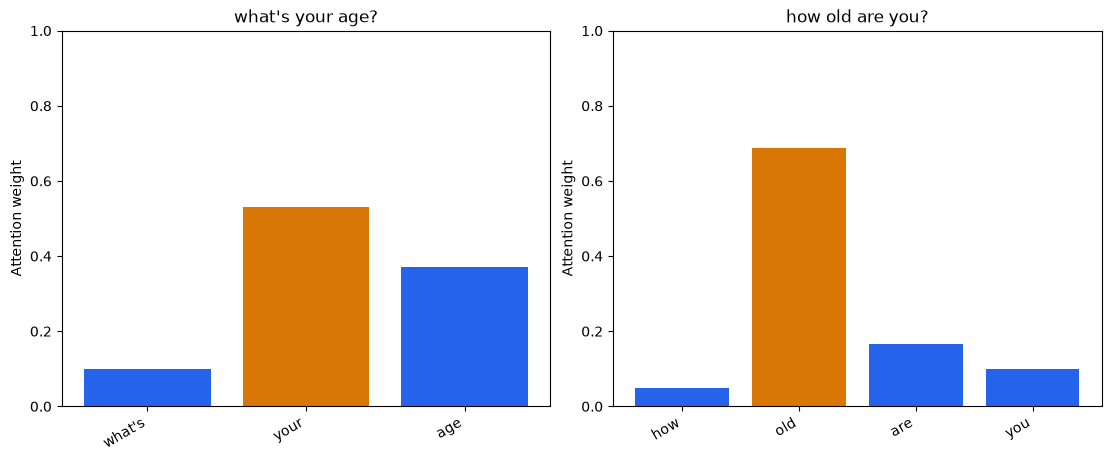

Both questions ask about age and are correctly assigned to answer group 1, but the highest-weight words differ: 'your' in the first question and 'old' in the second.
'Old' directly expresses age, whereas 'your' is a possessive word whose hidden state also includes the preceding context. The model can use different contextual cues to select the same answer.
This suggests that learned attention depends on wording, word position, and the surrounding sequence; it is not a fixed dictionary of important words or proof of semantic understanding.


In [8]:
similar_questions = ["what's your age?", "how old are you?"]
similar_indices = [df.index[df["question"].eq(question)][0] for question in similar_questions]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
task2_results = [show_attention(index, ax) for index, ax in zip(similar_indices, axes)]
plt.show()
print("Both questions ask about age and are correctly assigned to answer group 1, but the highest-weight words differ: 'your' in the first question and 'old' in the second.")
print("'Old' directly expresses age, whereas 'your' is a possessive word whose hidden state also includes the preceding context. The model can use different contextual cues to select the same answer.")
print("This suggests that learned attention depends on wording, word position, and the surrounding sequence; it is not a fixed dictionary of important words or proof of semantic understanding.")